# COMP 365 Individual Project — Practical Checkpoint 2

## Online Shopping Purchase Predictor
**Student:** Azalea Bolden  
**Course:** COMP 365 — AI & Machine Learning

### Project Question
How accurately can machine learning predict whether an online shopping session will result in a purchase based on customer browsing behavior?

### Continuation From Checkpoint 1
Checkpoint 1 established a working majority-class baseline and Logistic Regression model. The first model achieved about 88.1% accuracy, but purchase recall was only about 35.6%, meaning many actual purchases were missed.

### Checkpoint 2 Focus
This notebook continues the same project and directly addresses the instructor feedback by:

1. Investigating the 125 duplicate rows found in Checkpoint 1.
2. Removing exact duplicate records before the train/test split.
3. Treating `OperatingSystems`, `Browser`, `Region`, and `TrafficType` as categorical variables.
4. Retraining Logistic Regression after those preprocessing changes.
5. Adding Decision Tree and Random Forest models.
6. Testing class weighting to see whether purchase recall improves and what happens to precision.
7. Comparing all models on the same test cases.
8. Showing a weak case, sample predictions, and feature importance.

## 1. Install and Import Required Libraries

This notebook uses the same tools as Checkpoint 1:
- **pandas / NumPy** for data preparation
- **scikit-learn** for preprocessing, training, and evaluation
- **Matplotlib** for visualizations
- **ucimlrepo** for the official UCI dataset

The installation cell below only installs packages that are missing.

In [1]:
import importlib.util
import subprocess
import sys

required_packages = {
    "ucimlrepo": "ucimlrepo",
    "sklearn": "scikit-learn",
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib"
}

missing = [
    pip_name
    for import_name, pip_name in required_packages.items()
    if importlib.util.find_spec(import_name) is None
]

if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("Installation complete. If imports fail immediately after this cell, restart the kernel once.")
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Dataset

The project continues to use the **Online Shoppers Purchasing Intention Dataset** from the University of California, Irvine Machine Learning Repository.

The target variable is **Revenue**:
- `True` = Purchase
- `False` = No Purchase

In [3]:
shopping_data = fetch_ucirepo(id=468)

X_raw = shopping_data.data.features.copy()
y_raw = shopping_data.data.targets.copy()

if isinstance(y_raw, pd.DataFrame):
    y_raw = y_raw.iloc[:, 0]

df_raw = X_raw.copy()
df_raw["Revenue"] = y_raw

print("Dataset loaded successfully.")
print("Original dataset shape:", df_raw.shape)
print("Number of input features:", X_raw.shape[1])

Dataset loaded successfully.
Original dataset shape: (12330, 18)
Number of input features: 17


In [4]:
df_raw.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### Initial Data Check

This confirms that Checkpoint 2 is continuing to use the same real shopping-session dataset as Checkpoint 1.

In [5]:
print("Column names:")
print(df_raw.columns.tolist())

print("\nData types:")
print(df_raw.dtypes)

Column names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Data types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object


## 3. Data Quality and Duplicate Investigation

Checkpoint 1 found **125 duplicate rows**. The instructor asked that these be investigated and that identical records not appear in both the training and test sets.

The cells below:
1. check missing values,
2. count exact duplicates,
3. display sample duplicate records,
4. remove exact duplicate rows **before** the train/test split.

In [6]:
missing_values = df_raw.isnull().sum().sort_values(ascending=False)

print("Total missing values:", int(missing_values.sum()))
print("\nMissing values by column:")
print(missing_values)

Total missing values: 0

Missing values by column:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


In [7]:
duplicate_count = int(df_raw.duplicated().sum())

print("Exact duplicate rows after the first occurrence:", duplicate_count)

Exact duplicate rows after the first occurrence: 125


In [8]:
duplicate_rows = (
    df_raw[df_raw.duplicated(keep=False)]
    .sort_values(by=list(df_raw.columns))
)

print("Rows belonging to duplicate groups:", len(duplicate_rows))
duplicate_rows.head(10)

Rows belonging to duplicate groups: 201


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
8247,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,1,Returning_Visitor,True,False
10751,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,1,Returning_Visitor,True,False
11658,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,1,Returning_Visitor,True,False
8882,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,2,New_Visitor,False,False
11934,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,2,New_Visitor,False,False
11110,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,3,Returning_Visitor,False,False
12159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,3,Returning_Visitor,False,False
10341,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,4,1,Returning_Visitor,True,False
11801,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,4,1,Returning_Visitor,True,False
11938,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,4,1,Returning_Visitor,True,False


### Duplicate Decision

The repeated rows above are exact record-level duplicates across all available features and the target. For this checkpoint, exact duplicates are removed before splitting the data.

This reduces the risk that an identical observation could appear in both the training and test sets and make the model appear stronger than it really is.

In [9]:
df = df_raw.drop_duplicates().reset_index(drop=True)

print("Original rows:", len(df_raw))
print("Exact duplicates removed:", len(df_raw) - len(df))
print("Rows remaining:", len(df))
print("Duplicates remaining:", int(df.duplicated().sum()))

Original rows: 12330
Exact duplicates removed: 125
Rows remaining: 12205
Duplicates remaining: 0


## 4. Examine the Target Class Distribution

Class imbalance remains an important concern because Purchase sessions are much less common than No Purchase sessions.

In [10]:
X = df.drop(columns=["Revenue"]).copy()
y = df["Revenue"].copy()

if y.dtype == bool:
    y_binary = y.astype(int)
else:
    y_binary = (
        y.astype(str)
         .str.strip()
         .str.upper()
         .map({"TRUE": 1, "FALSE": 0, "1": 1, "0": 0})
    )

if y_binary.isnull().any():
    raise ValueError("Unexpected Revenue values found. Inspect y.unique() before continuing.")

class_counts = y_binary.value_counts().sort_index()
class_percent = (y_binary.value_counts(normalize=True).sort_index() * 100).round(2)

distribution = pd.DataFrame({
    "Sessions": class_counts,
    "Percent": class_percent
})
distribution.index = ["No Purchase", "Purchase"]

distribution

,Sessions,Percent
No Purchase,10297,84.37
Purchase,1908,15.63


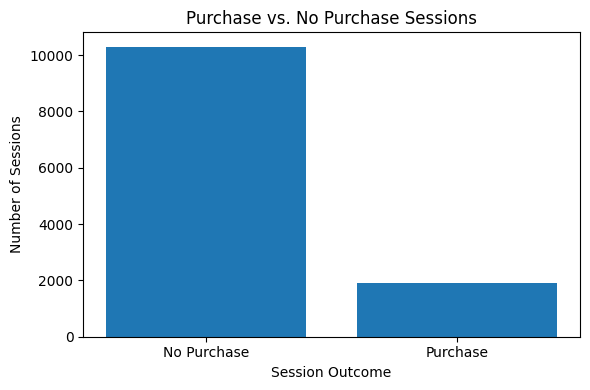

In [11]:
plt.figure(figsize=(6, 4))
plt.bar(distribution.index, distribution["Sessions"])
plt.title("Purchase vs. No Purchase Sessions")
plt.xlabel("Session Outcome")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()

### Class-Imbalance Observation

Because most sessions are No Purchase, accuracy by itself can make a model look stronger than it is. Purchase **recall**, **precision**, and **F1-score** remain important evaluation measures.

## 5. Prepare Features for Machine Learning

Checkpoint 1 automatically detected feature types from their stored data type. The instructor noted that four variables contain numeric **category codes**, not meaningful quantities:

- `OperatingSystems`
- `Browser`
- `Region`
- `TrafficType`

These four variables are now explicitly treated as categorical and one-hot encoded.

In [12]:
forced_categorical = [
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

auto_categorical = X.select_dtypes(exclude=["number"]).columns.tolist()

categorical_features = list(
    dict.fromkeys(auto_categorical + forced_categorical)
)

numeric_features = [
    column for column in X.columns
    if column not in categorical_features
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numeric_features)

Categorical features:
['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

Numerical features:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']


In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## 6. Create the Shared Training and Test Sets

The cleaned data is divided into:
- **80% training data**
- **20% test data**

A stratified split keeps the Purchase/No Purchase proportions similar in both sets.

Every model below is tested on this **same held-out test set** so the comparison is fair.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_binary,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_binary
)

print("Training cases:", len(X_train))
print("Test cases:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index().round(4))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).sort_index().round(4))

Training cases: 9764
Test cases: 2441

Training target distribution:
Revenue
0    0.8437
1    0.1563
Name: proportion, dtype: float64

Test target distribution:
Revenue
0    0.8435
1    0.1565
Name: proportion, dtype: float64


## 7. Shared Evaluation Function

All models are measured using:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion-matrix counts

The positive class is **Purchase**.

In [15]:
def evaluate_model(name, model):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(y_test, predictions).ravel()

    result = {
        "Model": name,
        "Test Cases": len(y_test),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

    return result, predictions

## 8. Majority-Class Baseline

As in Checkpoint 1, the non-AI baseline always predicts the most common class: **No Purchase**.

In [16]:
baseline_model = DummyClassifier(strategy="most_frequent")

baseline_result, baseline_pred = evaluate_model(
    "Majority-Class Baseline",
    baseline_model
)

pd.DataFrame([baseline_result]).round(4)

,Model,Test Cases,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,Majority-Class Baseline,2441,0.8435,0.0,0.0,0.0,2059,0,382,0


## 9. Logistic Regression

The original Checkpoint 1 model is retrained using:
- the duplicate-cleaned dataset,
- the corrected categorical variables,
- the same shared test set used by all Checkpoint 2 models.

In [17]:
logistic_model = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]
)

logistic_result, logistic_pred = evaluate_model(
    "Logistic Regression",
    logistic_model
)

pd.DataFrame([logistic_result]).round(4)

,Model,Test Cases,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,Logistic Regression,2441,0.8869,0.7524,0.4136,0.5338,2007,52,224,158


### Logistic Regression With Class Weighting

The balanced version gives the minority Purchase class more influence during training.

The main question is whether **recall improves**, and if so, whether **precision decreases**.

In [18]:
logistic_balanced_model = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]
)

logistic_balanced_result, logistic_balanced_pred = evaluate_model(
    "Logistic Regression + Balanced",
    logistic_balanced_model
)

pd.DataFrame([
    logistic_result,
    logistic_balanced_result
]).round(4)

,Model,Test Cases,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,Logistic Regression,2441,0.8869,0.7524,0.4136,0.5338,2007,52,224,158
1,Logistic Regression + Balanced,2441,0.8460,0.5050,0.7958,0.6179,1761,298,78,304


## 10. Decision Tree

Decision Tree is the second planned machine-learning model from the original project proposal.

In [19]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ))
    ]
)

decision_tree_result, decision_tree_pred = evaluate_model(
    "Decision Tree",
    decision_tree_model
)

pd.DataFrame([decision_tree_result]).round(4)

,Model,Test Cases,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,Decision Tree,2441,0.8566,0.54,0.5654,0.5524,1875,184,166,216


### Decision Tree With Class Weighting

In [20]:
decision_tree_balanced_model = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", DecisionTreeClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]
)

decision_tree_balanced_result, decision_tree_balanced_pred = evaluate_model(
    "Decision Tree + Balanced",
    decision_tree_balanced_model
)

pd.DataFrame([
    decision_tree_result,
    decision_tree_balanced_result
]).round(4)

,Model,Test Cases,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,Decision Tree,2441,0.8566,0.5400,0.5654,0.5524,1875,184,166,216
1,Decision Tree + Balanced,2441,0.8558,0.5412,0.5157,0.5282,1892,167,185,197


## 11. Random Forest

Random Forest is the third planned model from the original project proposal.

In [21]:
random_forest_model = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]
)

random_forest_result, random_forest_pred = evaluate_model(
    "Random Forest",
    random_forest_model
)

pd.DataFrame([random_forest_result]).round(4)

,Model,Test Cases,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,Random Forest,2441,0.9029,0.7617,0.5524,0.6404,1993,66,171,211


### Random Forest With Class Weighting

In [22]:
random_forest_balanced_model = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]
)

random_forest_balanced_result, random_forest_balanced_pred = evaluate_model(
    "Random Forest + Balanced",
    random_forest_balanced_model
)

pd.DataFrame([
    random_forest_result,
    random_forest_balanced_result
]).round(4)

,Model,Test Cases,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,Random Forest,2441,0.9029,0.7617,0.5524,0.6404,1993,66,171,211
1,Random Forest + Balanced,2441,0.8931,0.7266,0.5079,0.5978,1986,73,188,194


## 12. Full Checkpoint 2 Model Comparison

This is the main comparison table for Checkpoint 2.

All seven methods below were evaluated using the **same test cases**.

In [23]:
all_results = pd.DataFrame([
    baseline_result,
    logistic_result,
    logistic_balanced_result,
    decision_tree_result,
    decision_tree_balanced_result,
    random_forest_result,
    random_forest_balanced_result
])

comparison_table = all_results[
    [
        "Model",
        "Test Cases",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "FP",
        "FN",
        "TP"
    ]
].copy()

comparison_table.round(4)

,Model,Test Cases,Accuracy,Precision,Recall,F1-score,FP,FN,TP
0,Majority-Class Baseline,2441,0.8435,0.0000,0.0000,0.0000,0,382,0
1,Logistic Regression,2441,0.8869,0.7524,0.4136,0.5338,52,224,158
2,Logistic Regression + Balanced,2441,0.8460,0.5050,0.7958,0.6179,298,78,304
3,Decision Tree,2441,0.8566,0.5400,0.5654,0.5524,184,166,216
4,Decision Tree + Balanced,2441,0.8558,0.5412,0.5157,0.5282,167,185,197
5,Random Forest,2441,0.9029,0.7617,0.5524,0.6404,66,171,211
6,Random Forest + Balanced,2441,0.8931,0.7266,0.5079,0.5978,73,188,194


## 13. Test the Precision–Recall Tradeoff

The instructor specifically asked whether class weighting improves Purchase recall and what happens to precision.

The next cell compares each standard model directly with its balanced version.

In [24]:
def compare_weighting(model_name, regular, balanced):
    recall_change = balanced["Recall"] - regular["Recall"]
    precision_change = balanced["Precision"] - regular["Precision"]

    print(model_name)
    print("-" * len(model_name))
    print(
        f"Recall:    {regular['Recall']:.3f} -> "
        f"{balanced['Recall']:.3f} ({recall_change:+.3f})"
    )
    print(
        f"Precision: {regular['Precision']:.3f} -> "
        f"{balanced['Precision']:.3f} ({precision_change:+.3f})"
    )

    if recall_change > 0 and precision_change < 0:
        print(
            "Result: Class weighting caught more actual purchases, "
            "but produced more false-positive Purchase predictions."
        )
    elif recall_change > 0 and precision_change >= 0:
        print(
            "Result: Class weighting improved recall without reducing precision."
        )
    elif recall_change <= 0:
        print(
            "Result: Class weighting did not improve Purchase recall for this model."
        )
    print()

compare_weighting(
    "Logistic Regression",
    logistic_result,
    logistic_balanced_result
)

compare_weighting(
    "Decision Tree",
    decision_tree_result,
    decision_tree_balanced_result
)

compare_weighting(
    "Random Forest",
    random_forest_result,
    random_forest_balanced_result
)

Logistic Regression
-------------------
Recall:    0.414 -> 0.796 (+0.382)
Precision: 0.752 -> 0.505 (-0.247)
Result: Class weighting caught more actual purchases, but produced more false-positive Purchase predictions.

Decision Tree
-------------
Recall:    0.565 -> 0.516 (-0.050)
Precision: 0.540 -> 0.541 (+0.001)
Result: Class weighting did not improve Purchase recall for this model.

Random Forest
-------------
Recall:    0.552 -> 0.508 (-0.045)
Precision: 0.762 -> 0.727 (-0.035)
Result: Class weighting did not improve Purchase recall for this model.



## 14. Select the Strongest Current Model

Because Purchase is the minority class, the strongest model is not selected using accuracy alone.

For this checkpoint, the notebook identifies the model with the highest **F1-score**, while precision and recall are still reported separately.

In [25]:
model_lookup = {
    "Logistic Regression": (logistic_model, logistic_pred),
    "Logistic Regression + Balanced": (
        logistic_balanced_model,
        logistic_balanced_pred
    ),
    "Decision Tree": (
        decision_tree_model,
        decision_tree_pred
    ),
    "Decision Tree + Balanced": (
        decision_tree_balanced_model,
        decision_tree_balanced_pred
    ),
    "Random Forest": (
        random_forest_model,
        random_forest_pred
    ),
    "Random Forest + Balanced": (
        random_forest_balanced_model,
        random_forest_balanced_pred
    )
}

ml_results = all_results[
    all_results["Model"] != "Majority-Class Baseline"
].copy()

best_row = (
    ml_results
    .sort_values("F1-score", ascending=False)
    .iloc[0]
)

best_model_name = best_row["Model"]
best_model, best_predictions = model_lookup[best_model_name]

print("Strongest current model by F1-score:", best_model_name)
print(f"Accuracy:  {best_row['Accuracy']:.3f}")
print(f"Precision: {best_row['Precision']:.3f}")
print(f"Recall:    {best_row['Recall']:.3f}")
print(f"F1-score:  {best_row['F1-score']:.3f}")

Strongest current model by F1-score: Random Forest
Accuracy:  0.903
Precision: 0.762
Recall:    0.552
F1-score:  0.640


## 15. Confusion Matrix for the Strongest Current Model

This gives a visual breakdown of:
- correct No Purchase predictions,
- false Purchase predictions,
- missed purchases,
- correctly detected purchases.

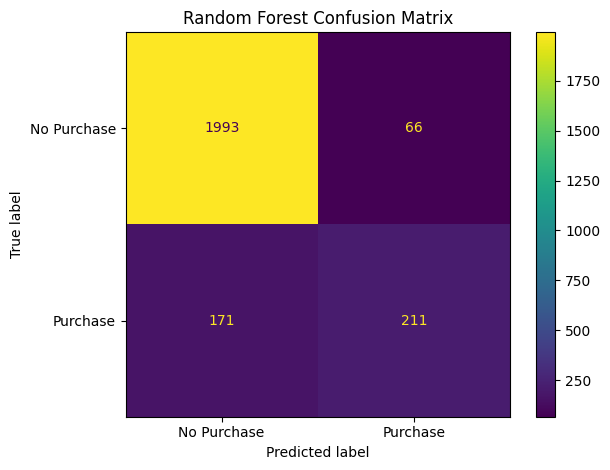

In [26]:
cm = confusion_matrix(y_test, best_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Purchase", "Purchase"]
)

disp.plot()
plt.title(f"{best_model_name} Confusion Matrix")
plt.tight_layout()
plt.show()

## 16. Weak Case / Failure Example

Checkpoint 2 requires a weak result or failure case.

The next cell finds one **actual Purchase session that the selected model predicted as No Purchase**, if such a case exists.

In [27]:
false_negative_mask = (y_test == 1) & (best_predictions == 0)
false_negative_indices = y_test.index[false_negative_mask]

if len(false_negative_indices) > 0:
    weak_index = false_negative_indices[0]
    weak_case = X_test.loc[[weak_index]].copy()

    weak_case["Actual Outcome"] = "Purchase"
    weak_case["Predicted Outcome"] = "No Purchase"

    if hasattr(best_model, "predict_proba"):
        weak_probability = best_model.predict_proba(
            X_test.loc[[weak_index]]
        )[:, 1][0]

        weak_case["Purchase Probability"] = round(
            float(weak_probability),
            3
        )

    print("Weak case: an actual Purchase session that the model missed.")
    display(weak_case)
else:
    print(
        "The selected model produced no false-negative Purchase cases "
        "on this test set."
    )

Weak case: an actual Purchase session that the model missed.


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Actual Outcome,Predicted Outcome,Purchase Probability
7769,10,471.06,0,0.0,171,5830.91,0.001099,0.005495,0.0,0.0,Oct,2,10,4,2,Returning_Visitor,False,Purchase,No Purchase,0.105


### Weak-Case Interpretation

A missed Purchase demonstrates that the model can still fail to identify high-intent sessions.

Possible explanations include:
- the imbalance between Purchase and No Purchase examples,
- overlap between the browsing patterns of buyers and non-buyers,
- limits in the available features,
- or the model's decision boundary.

This single case does not prove which factor caused the error.

## 17. Example Outputs

These predictions demonstrate that the current artifact accepts real held-out shopping sessions and produces observable Purchase / No Purchase outputs.

In [28]:
sample_X = X_test.head(10).copy()
sample_actual = y_test.loc[sample_X.index]

sample_predictions = best_model.predict(sample_X)

sample_results = pd.DataFrame({
    "Actual": sample_actual.map({
        0: "No Purchase",
        1: "Purchase"
    }).values,
    "Predicted": pd.Series(sample_predictions).map({
        0: "No Purchase",
        1: "Purchase"
    }).values
}, index=sample_X.index)

if hasattr(best_model, "predict_proba"):
    sample_probabilities = best_model.predict_proba(sample_X)[:, 1]
    sample_results["Purchase Probability"] = np.round(
        sample_probabilities,
        3
    )

sample_results

,Actual,Predicted,Purchase Probability
11640,No Purchase,No Purchase,0.030
6936,No Purchase,No Purchase,0.040
7194,No Purchase,No Purchase,0.090
11263,No Purchase,No Purchase,0.050
4728,No Purchase,No Purchase,0.000
9878,No Purchase,Purchase,0.585
8101,No Purchase,No Purchase,0.035
6642,No Purchase,No Purchase,0.065
10215,No Purchase,No Purchase,0.105
10224,No Purchase,No Purchase,0.030


## 18. Feature Importance

The project proposal planned feature interpretation. Random Forest provides feature-importance values that can help show which processed variables contributed most to its predictions.

These values show model importance, **not causation**.

In [29]:
if (
    random_forest_balanced_result["F1-score"]
    >= random_forest_result["F1-score"]
):
    feature_model = random_forest_balanced_model
    feature_model_name = "Random Forest + Balanced"
else:
    feature_model = random_forest_model
    feature_model_name = "Random Forest"

fitted_preprocessor = feature_model.named_steps["preprocess"]
fitted_forest = feature_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()
feature_values = fitted_forest.feature_importances_

feature_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": feature_values
    })
    .sort_values("Importance", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

print("Feature importance from:", feature_model_name)
feature_importance

Feature importance from: Random Forest


,Feature,Importance
0,num__PageValues,0.316440
1,num__ExitRates,0.083191
2,num__ProductRelated_Duration,0.079932
3,num__ProductRelated,0.069988
4,num__Administrative_Duration,0.053497
5,num__BounceRates,0.050984
6,num__Administrative,0.043409
7,num__Informational_Duration,0.026342
8,cat__Month_Nov,0.020455
9,num__Informational,0.018887


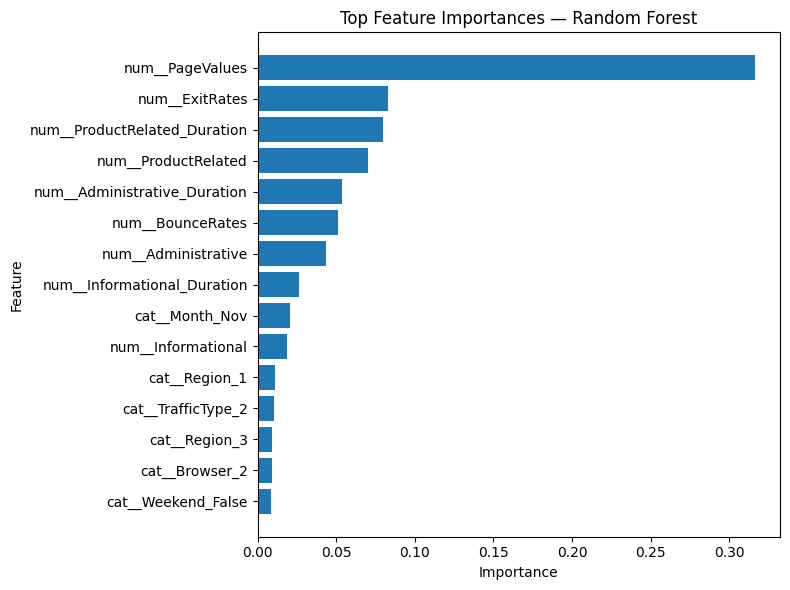

In [30]:
plot_data = feature_importance.sort_values("Importance")

plt.figure(figsize=(8, 6))
plt.barh(
    plot_data["Feature"],
    plot_data["Importance"]
)
plt.title(f"Top Feature Importances — {feature_model_name}")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 19. Checkpoint 2 Result Summary

After running the notebook, this cell prints the numbers that should be transferred into the Checkpoint 2 report.

In [31]:
print("CHECKPOINT 2 RESULT SUMMARY")
print("=" * 35)

print(f"Original rows: {len(df_raw):,}")
print(f"Exact duplicates removed: {len(df_raw) - len(df):,}")
print(f"Cleaned rows: {len(df):,}")
print(f"Training cases: {len(X_train):,}")
print(f"Test cases: {len(X_test):,}")

print("\nCorrected categorical variables:")
print(", ".join(forced_categorical))

print("\nStrongest model by F1-score:")
print(best_model_name)
print(f"Accuracy:  {best_row['Accuracy']:.3f}")
print(f"Precision: {best_row['Precision']:.3f}")
print(f"Recall:    {best_row['Recall']:.3f}")
print(f"F1-score:  {best_row['F1-score']:.3f}")

print("\nFull model comparison:")
display(comparison_table.round(4))

CHECKPOINT 2 RESULT SUMMARY
Original rows: 12,330
Exact duplicates removed: 125
Cleaned rows: 12,205
Training cases: 9,764
Test cases: 2,441

Corrected categorical variables:
OperatingSystems, Browser, Region, TrafficType

Strongest model by F1-score:
Random Forest
Accuracy:  0.903
Precision: 0.762
Recall:    0.552
F1-score:  0.640

Full model comparison:


,Model,Test Cases,Accuracy,Precision,Recall,F1-score,FP,FN,TP
0,Majority-Class Baseline,2441,0.8435,0.0000,0.0000,0.0000,0,382,0
1,Logistic Regression,2441,0.8869,0.7524,0.4136,0.5338,52,224,158
2,Logistic Regression + Balanced,2441,0.8460,0.5050,0.7958,0.6179,298,78,304
3,Decision Tree,2441,0.8566,0.5400,0.5654,0.5524,184,166,216
4,Decision Tree + Balanced,2441,0.8558,0.5412,0.5157,0.5282,167,185,197
5,Random Forest,2441,0.9029,0.7617,0.5524,0.6404,66,171,211
6,Random Forest + Balanced,2441,0.8931,0.7266,0.5079,0.5978,73,188,194


## 20. What the Current Tests Show

The Checkpoint 2 tests can show:
- how performance changes after removing exact duplicates,
- how performance changes after correcting coded categorical variables,
- how Logistic Regression compares with Decision Tree and Random Forest,
- whether class weighting improves Purchase recall,
- and what precision is lost or gained when recall changes.

The current tests **cannot** prove that the selected model will generalize to every e-commerce website or future customer population.

## 21. Current Limitations

At Practical Checkpoint 2:

- The dataset represents one e-commerce context and may not generalize to every retailer.
- Purchase remains the minority class.
- A single train/test split does not capture every possible sample variation.
- Higher recall may come with lower precision.
- Feature importance does not establish that a feature causes a purchase.
- The Streamlit interface is still a final-project task.

## 22. Next Steps Before the Final Project

### 1. Finalize model selection and evaluation
Use the Checkpoint 2 comparison to select the most appropriate model, verify the precision/recall tradeoff, and finalize the main results and visualizations.

### 2. Build the Streamlit interface
Connect the selected model to a simple user interface that accepts shopping-session inputs and returns a Purchase / No Purchase prediction.

## 23. Preliminary Paper Outline

**Introduction:**  
This project investigates whether online browsing behavior can be used to predict whether an online shopping session will result in a purchase.

**Methods:**  
The project uses the UCI Online Shoppers Purchasing Intention dataset, removes exact duplicates before splitting, treats coded category variables appropriately, and compares a majority-class baseline with Logistic Regression, Decision Tree, and Random Forest models, including class-weighted versions.

**Results:**  
The results compare accuracy, precision, recall, and F1-score on the same held-out test set and evaluate whether class weighting improves detection of actual Purchase sessions.

**Limitations:**  
The dataset is imbalanced and represents a specific e-commerce setting, so the model may not generalize to all retailers or future browsing behavior.

## 24. Dataset and External Tools

**Dataset:**  
Sakar, C. & Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository.  
https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset

**External Python libraries used:**  
- pandas
- NumPy
- Matplotlib
- scikit-learn
- ucimlrepo

**AI-assisted development disclosure:**  
ChatGPT was used to assist with planning, code organization, explanations, and debugging support. All data, model metrics, confusion matrices, predictions, and comparison results reported for the project should come from the executed notebook.

## 25. Save the Final Model for Streamlit

The model comparison showed that the standard **Random Forest** had the strongest overall F1-score. This cell saves the fitted Random Forest pipeline so the Streamlit application can load the exact same preprocessing and model together.


In [32]:
from pathlib import Path
import joblib

artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)

# random_forest_model was already fitted during the model comparison above.
model_path = artifact_dir / 'random_forest_pipeline.joblib'
joblib.dump(random_forest_model, model_path)

print(f'Saved final model to: {model_path.resolve()}')


Saved final model to: C:\Users\Azalea Bolden\OneDrive\Documents\NCAT\Fall 2026\COMP365\Online_Shopping_Predictor_Final_Project_Through_Streamlit\artifacts\random_forest_pipeline.joblib


## 26. Streamlit Demo Readiness Check

Before launching the app, confirm that the model file exists. The Streamlit interface uses this file to generate Purchase / No Purchase predictions from user-entered shopping-session information.


In [33]:
from pathlib import Path

model_path = Path('artifacts/random_forest_pipeline.joblib')
print('Model ready for Streamlit:', model_path.exists())
print('Expected file:', model_path.resolve())


Model ready for Streamlit: True
Expected file: C:\Users\Azalea Bolden\OneDrive\Documents\NCAT\Fall 2026\COMP365\Online_Shopping_Predictor_Final_Project_Through_Streamlit\artifacts\random_forest_pipeline.joblib
